# 03 — Image features + image-only model

Inputs: `alprotein_outputs/` from notebooks 01–02 and the images in the dataset folder.

Plan:
1. Pick the images taken on the two measurement days (t0 = 7 June, t1 = 13 June), around 10:00 and 14:00.
2. Find the walkway in each image automatically and split each image into **two beds** (6 plants each),
   then each bed into a **2 × 3 grid of cells** (one cell ≈ one plant, approximate — see assumptions).
3. Two kinds of image features per region and day:
   - **hand-crafted, biologically meaningful**: green-canopy fraction, flower (yellow) fraction, fruit (red) fraction, greenness, texture, brightness
   - **pretrained CNN embeddings** (ResNet-50, ImageNet) → reduced with PCA inside the CV folds
4. Check that a cell really describes **its own** plant (cell features vs the plant's manual measurements, permutation test).
5. Image-only models (Ridge / Random Forest), same target and same CV as notebook 02 — with all images (t0 + t1) and with **t0 images only** (a true forecast, made before the growth happens).

In [1]:
# --- Setup -------------------------------------------------------------------
import os, json
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image, ImageDraw
from scipy.ndimage import uniform_filter1d

try:
    from google.colab import drive
    drive.mount('/content/drive')
    IN_COLAB = True
except ImportError:
    IN_COLAB = False

# EDIT THIS if needed: same DATA_DIR as notebooks 01–02
DATA_DIR = Path('/content/drive/MyDrive/25 tomato dataset') if IN_COLAB else Path(os.environ.get('DATA_DIR', 'data'))
MONTH_DIR = DATA_DIR / '2025' / '202506'
OUT_DIR = DATA_DIR.parent / 'alprotein_outputs'
assert (OUT_DIR / 'model_table_numerical.parquet').exists(), 'Run notebooks 01 and 02 first'

SEED = 42
np.random.seed(SEED)
pd.set_option('display.width', 200)
pd.set_option('display.max_columns', 40)

images = pd.read_parquet(OUT_DIR / 'image_index.parquet')
data = pd.read_parquet(OUT_DIR / 'model_table_numerical.parquet')
win = json.loads((OUT_DIR / 'target_window.json').read_text())
T0, T1 = pd.Timestamp(win['T0']), pd.Timestamp(win['T1'])
print('t0 =', T0.date(), ' t1 =', T1.date(), '|', len(images), 'images indexed |', len(data), 'plants')

Mounted at /content/drive
t0 = 2025-06-07  t1 = 2025-06-13 | 745 images indexed | 60 plants


## 1. Choose the images

Lighting changes a lot during the day (shadows, glare), so we only use images taken around **10:00 and 14:00**
on t0 and t1, and average the features of the images of the same day. If a camera has no image at those hours,
any image between 08:00 and 16:00 is used instead.

In [2]:
PREFERRED_HOURS = [10, 14]
FALLBACK_HOURS = range(8, 17)

images['folder'] = images['path'].str.split('/').str[1]          # e.g. '111,211' (with comma)
sel = []
for (cam, day), g in images[images.date.isin([T0, T1])].groupby(['camera', 'date']):
    pick = g[g.hour.isin(PREFERRED_HOURS)]
    if pick.empty:
        pick = g[g.hour.isin(FALLBACK_HOURS)]
    sel.append(pick)
sel = pd.concat(sel).reset_index(drop=True)
sel['day'] = np.where(sel['date'] == T0, 't0', 't1')
display(sel.pivot_table(index='camera', columns='day', values='path', aggfunc='size'))

day,t0,t1
camera,,
111211,2,1
11411,2,2
214311,2,2
511611,2,2
514614,2,2


## 2. Plant → position in the image

From the camera folder name and the *Plant Orientation Diagram*:
- folder `111,211` → **left bed** = plants starting at 111 (111–113, 121–123), **right bed** = plants starting at 211.
- inside a bed: **left column = variety 1, right column = variety 2**; rows top → bottom = replicate 1, 2, 3.

**Assumption:** the canopy is closed by June and leaves overlap, so a cell is an *approximate* plant region.
Bed-level features (6 plants) are more reliable than cell-level ones.

In [3]:
def bed_plants(token):
    """'111' -> {plant: (col, row)} for L111..L113 (col 0) and L121..L123 (col 1); '11' -> CK11..CK23."""
    out = {}
    if len(token) == 2:                     # control group, e.g. '11' -> CK11..CK13, CK21..CK23
        for v in (1, 2):
            for i, r in enumerate(range(1, 4)):
                out[f'CK{v}{r}'] = (v - 1, i)
    else:
        t, r0 = token[0], int(token[2])
        for v in (1, 2):
            for i, r in enumerate(range(r0, r0 + 3)):
                out[f'L{t}{v}{r}'] = (v - 1, i)
    return out

layout = []
for folder in images['folder'].unique():
    left, right = folder.split(',')
    for side, tok in (('L', left), ('R', right)):
        for plant, (col, row) in bed_plants(tok).items():
            layout.append({'folder': folder, 'camera': folder.replace(',', ''), 'plant': plant,
                           'bed': side, 'col': col, 'row': row})
layout = pd.DataFrame(layout)
missing = set(data.plant) - set(layout.plant)
print('plants without an image position:', missing or 'none')
display(layout.pivot_table(index=['camera', 'row'], columns=['bed', 'col'], values='plant', aggfunc='first'))

plants without an image position: none


bed            L           R      
col            0     1     0     1
camera row                        
111211 0    L111  L121  L211  L221
       1    L112  L122  L212  L222
       2    L113  L123  L213  L223
11411  0    CK11  CK21  L411  L421
       1    CK12  CK22  L412  L422
       2    CK13  CK23  L413  L423
214311 0    L214  L224  L311  L321
       1    L215  L225  L312  L322
       2    L216  L226  L313  L323
511611 0    L511  L521  L611  L621
       1    L512  L522  L612  L622
       2    L513  L523  L613  L623
514614 0    L514  L524  L614  L624
       1    L515  L525  L615  L625
       2    L516  L526  L616  L626

## 3. Walkway detection + regions + hand-crafted features

In [4]:
WIDTH = 960   # work on downscaled images (originals are 3840 px wide)

def load(rel_path):
    im = Image.open(MONTH_DIR / rel_path).convert('RGB')
    h = int(im.height * WIDTH / im.width)
    return np.asarray(im.resize((WIDTH, h), Image.BILINEAR)).astype(np.float32) / 255

def colour_masks(a):
    r, g, b = a[..., 0], a[..., 1], a[..., 2]
    s = r + g + b + 1e-6
    exg = (2 * g - r - b) / s                                  # excess-green index (chromatic)
    mx, mn = a.max(-1), a.min(-1)
    sat = (mx - mn) / (mx + 1e-6)
    veg = exg > 0.10                                           # green canopy
    yellow = (r > .45) & (g > .40) & (b < .6 * g) & (sat > .35) & (np.abs(r - g) < .25)   # flowers
    red = (r > .45) & (r > 1.4 * g) & (r > 1.4 * b)            # ripening fruit
    return veg, yellow, red, exg

def find_walkway(veg):
    """Widest run of columns with little vegetation in the middle 60 % of the image."""
    W = veg.shape[1]
    col = uniform_filter1d(veg.mean(0), size=max(3, W // 40))
    lo, hi = int(.2 * W), int(.8 * W)
    low = col < 0.25
    best, start = (0, int(.4 * W), int(.6 * W)), None
    for x in range(lo, hi + 1):
        if x < hi and low[x]:
            start = x if start is None else start
        elif start is not None:
            if x - start > best[0]:
                best = (x - start, start, x)
            start = None
    return best[1], best[2]

def regions(a, x0, x1):
    """Bed boxes and 2x3 cell boxes: (y0, y1, xa, xb)."""
    H, W = a.shape[:2]
    out = {}
    for bed, (xa, xb) in (('L', (0, x0)), ('R', (x1, W))):
        out[(bed, None, None)] = (0, H, xa, xb)
        xm = (xa + xb) // 2
        for col, (ca, cb) in enumerate(((xa, xm), (xm, xb))):
            for row in range(3):
                out[(bed, col, row)] = (H * row // 3, H * (row + 1) // 3, ca, cb)
    return out

def handcrafted(a, veg, yellow, red, exg, box):
    y0, y1, xa, xb = box
    sl = (slice(y0, y1), slice(xa, xb))
    v = veg[sl]
    gray = a[sl].mean(-1)
    gy, gx = np.gradient(gray)
    return {
        'veg_frac': v.mean(),
        'yellow_frac': yellow[sl].mean(),
        'red_frac': red[sl].mean(),
        'exg_mean_veg': exg[sl][v].mean() if v.any() else np.nan,
        'brightness': gray.mean(),
        'texture_std_veg': gray[v].std() if v.any() else np.nan,
        'edge_density': (np.hypot(gx, gy) > 0.08).mean(),
    }

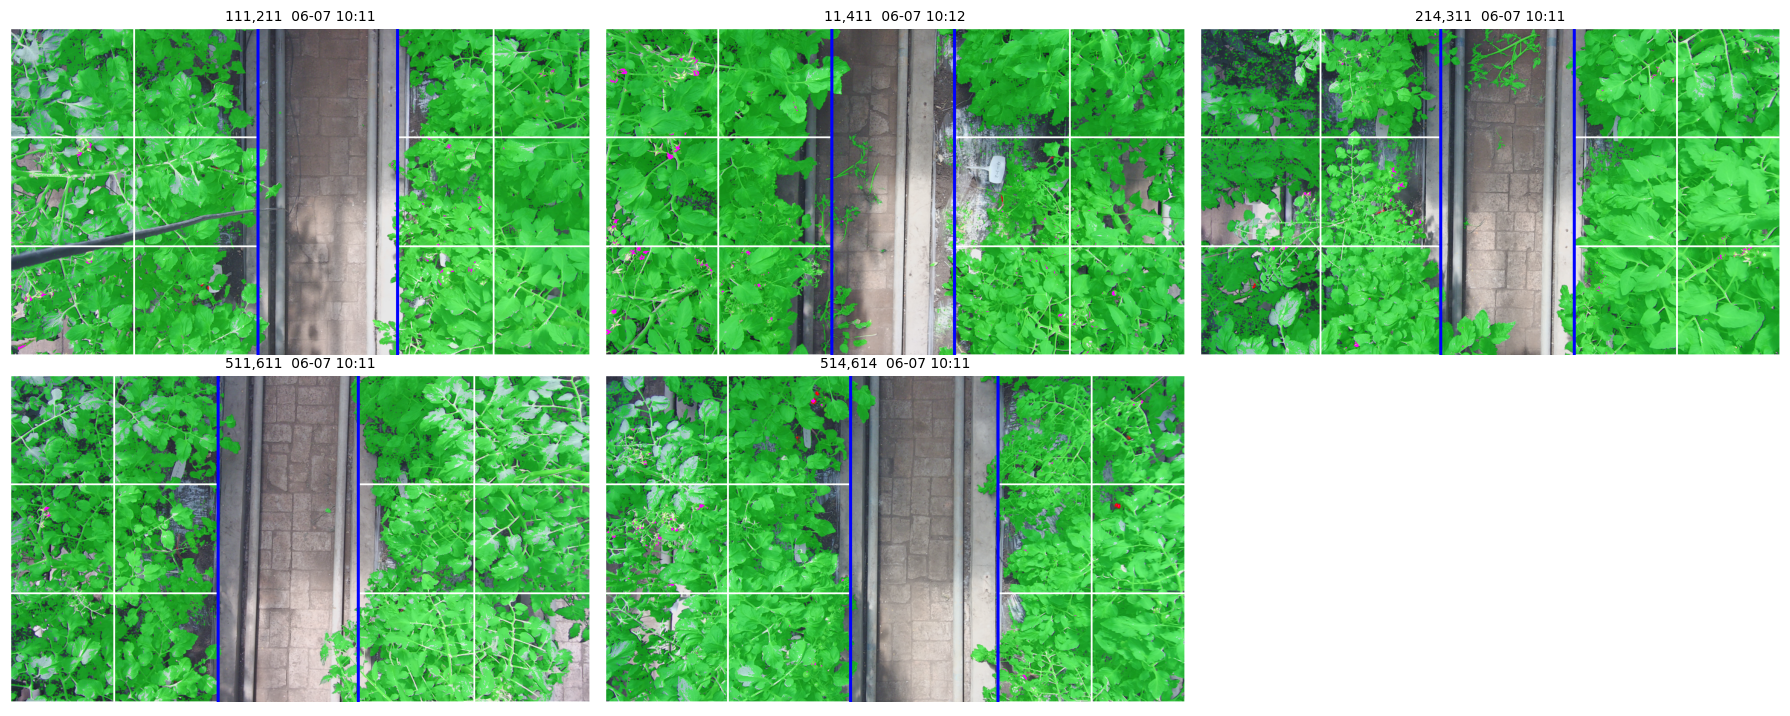

In [5]:
# Visual check: walkway (blue), cells (white), canopy mask (green), flowers (magenta), fruit (red) — t0, one image per camera
qc = sel[sel.day == 't0'].groupby('camera').head(1)
fig, axes = plt.subplots(int(np.ceil(len(qc) / 3)), 3, figsize=(18, 3.6 * np.ceil(len(qc) / 3)))
for ax, (_, r) in zip(axes.ravel(), qc.iterrows()):
    a = load(r.path); veg, yel, red, exg = colour_masks(a); x0, x1 = find_walkway(veg)
    vis = (a * 255).astype(np.uint8)
    vis[veg] = (vis[veg] * .55 + np.array([0, 255, 0]) * .45).astype(np.uint8)
    vis[yel] = [255, 0, 255]; vis[red] = [255, 0, 0]
    im = Image.fromarray(vis); d = ImageDraw.Draw(im)
    for (bed, col, row), (y0, y1, xa, xb) in regions(a, x0, x1).items():
        if col is not None:
            d.rectangle([xa, y0, xb, y1], outline='white', width=2)
    for x in (x0, x1):
        d.line([(x, 0), (x, a.shape[0])], fill='blue', width=5)
    ax.imshow(im); ax.set_title(f'{r.folder}  {r.capture_local:%m-%d %H:%M}', fontsize=10); ax.axis('off')
for ax in axes.ravel()[len(qc):]:
    ax.axis('off')
plt.tight_layout(); plt.show()

## 3b. Illumination correction with the walkway

Images on 13 June are brighter/hazier than on 7 June for every camera, so raw colour features change with the weather.
The walkway (grey bricks) does not change, so we use it as a reference: for each image we take the median colour of the
walkway and rescale each RGB channel so that the walkway matches the median walkway colour of all selected images
(a per-channel gain = simple white balance). A full affine correction (matching mean **and** contrast) was tried during
development and over-corrected, so the simpler gain is used.

In [6]:
def walkway_colour(a, x0, x1, margin=5):
    w = a[:, x0 + margin:max(x0 + margin + 1, x1 - margin)].reshape(-1, 3)
    return np.median(w, axis=0)

norm_rows = []
for _, r in sel.iterrows():
    a = load(r.path)
    veg, *_ = colour_masks(a)
    x0, x1 = find_walkway(veg)
    norm_rows.append({'path': r.path, 'camera': r.camera, 'day': r.day, 'x0': x0, 'x1': x1,
                      **dict(zip(['walk_r', 'walk_g', 'walk_b'], walkway_colour(a, x0, x1)))})
norm = pd.DataFrame(norm_rows)
REF = norm[['walk_r', 'walk_g', 'walk_b']].median().values
norm[['gain_r', 'gain_g', 'gain_b']] = REF / norm[['walk_r', 'walk_g', 'walk_b']].values
print('reference walkway colour (RGB):', REF.round(3))
display(norm.groupby(['camera', 'day'])[['walk_r', 'walk_g', 'walk_b', 'gain_r', 'gain_g', 'gain_b']].mean().round(3))

GAINS = norm.set_index('path')[['gain_r', 'gain_g', 'gain_b']]
def normalise(a, path):
    return np.clip(a * GAINS.loc[path].values, 0, 1)

reference walkway colour (RGB): [0.545 0.51  0.522]


walk_r  walk_g  walk_b  gain_r  gain_g  gain_b
camera day                                                
111211 t0    0.508   0.471   0.478   1.074   1.084   1.090
       t1    0.592   0.529   0.537   0.921   0.963   0.971
11411  t0    0.537   0.508   0.500   1.015   1.006   1.044
       t1    0.567   0.535   0.533   0.962   0.952   0.978
214311 t0    0.533   0.506   0.512   1.023   1.011   1.019
       t1    0.565   0.512   0.520   0.969   1.000   1.008
511611 t0    0.547   0.504   0.520   0.997   1.012   1.004
       t1    0.608   0.547   0.569   0.901   0.936   0.920
514614 t0    0.551   0.522   0.531   0.990   0.978   0.982
       t1    0.588   0.543   0.545   0.935   0.942   0.962

## 4. Pretrained CNN embeddings

ResNet-50 pretrained on ImageNet, classification head removed → a 2048-number description of each crop.
The network is **not trained** on our data (60 samples are far too few); we only use it as a feature extractor.

In [7]:
import torch, torchvision
from torchvision import transforms

DEVICE = 'cuda' if torch.cuda.is_available() else 'cpu'
print('device:', DEVICE)

def get_backbone():
    try:
        weights = torchvision.models.ResNet50_Weights.IMAGENET1K_V2
        net = torchvision.models.resnet50(weights=weights)
    except Exception as e:
        if os.environ.get('ALLOW_RANDOM_CNN'):          # only for offline testing of the code path
            print('WARNING: pretrained weights not available, using random weights:', e)
            net = torchvision.models.resnet50(weights=None)
        else:
            raise
    net.fc = torch.nn.Identity()
    return net.eval().to(DEVICE)

backbone = get_backbone()
to_tensor = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225]),
])

@torch.no_grad()
def embed(crops):
    x = torch.stack([to_tensor(Image.fromarray((c * 255).astype(np.uint8))) for c in crops]).to(DEVICE)
    return backbone(x).cpu().numpy()

device: cuda
Downloading: "https://download.pytorch.org/models/resnet50-11ad3fa6.pth" to /root/.cache/torch/hub/checkpoints/resnet50-11ad3fa6.pth


100%|██████████| 97.8M/97.8M [00:00<00:00, 193MB/s]


## 5. Extract features for every selected image (cached on Drive)

In [8]:
CACHE = OUT_DIR / 'image_region_features_v2.parquet'       # v2 = with illumination correction
EMB_CACHE = OUT_DIR / 'image_region_embeddings_v2.npy'
FORCE = False          # set True to recompute (needed if you change the feature code)

if CACHE.exists() and EMB_CACHE.exists() and not FORCE:
    feats = pd.read_parquet(CACHE)
    embs = np.load(EMB_CACHE)
    print('loaded cache:', feats.shape, embs.shape)
else:
    rows, emb_list, box_rows = [], [], []
    for i, r in sel.reset_index(drop=True).iterrows():
        raw = load(r.path)
        veg_raw, yel_raw, red_raw, exg_raw = colour_masks(raw)
        x0, x1 = find_walkway(veg_raw)                       # walkway found on the raw image
        a = normalise(raw, r.path)                            # features on the corrected image
        veg, yel, red, exg = colour_masks(a)
        regs = regions(a, x0, x1)
        crops = []
        for (bed, col, row), box in regs.items():
            f = handcrafted(a, veg, yel, red, exg, box)
            if col is None:                                   # keep raw values at bed level to show the effect
                fr = handcrafted(raw, veg_raw, yel_raw, red_raw, exg_raw, box)
                f.update({'raw_veg_frac': fr['veg_frac'], 'raw_brightness': fr['brightness']})
            rows.append({'path': r.path, 'camera': r.camera, 'folder': r.folder, 'day': r.day,
                         'hour': r.hour, 'bed': bed, 'col': col, 'row': row,
                         'walk_x0': x0 / WIDTH, 'walk_x1': x1 / WIDTH, **f})
            y0, y1, xa, xb = box
            box_rows.append({'path': r.path, 'folder': r.folder, 'day': r.day, 'bed': bed, 'col': col, 'row': row,
                             'y0': y0, 'y1': y1, 'xa': xa, 'xb': xb, 'width': WIDTH})
            crops.append(a[y0:y1, xa:xb])
        emb_list.append(embed(crops))
        print(f'{i + 1}/{len(sel)}', r.path, end='\r')
    feats = pd.DataFrame(rows)
    embs = np.concatenate(emb_list)
    feats.to_parquet(CACHE, index=False)
    np.save(EMB_CACHE, embs)
    pd.DataFrame(box_rows).to_parquet(OUT_DIR / 'image_regions.parquet', index=False)   # used by notebook 04
    print('\nextracted:', feats.shape, embs.shape)

feats['emb_idx'] = np.arange(len(feats))
bed_level = feats[feats['col'].isna()]
check = bed_level.pivot_table(index=['camera', 'bed'], columns='day', values=['raw_veg_frac', 'veg_frac', 'raw_brightness', 'brightness'])
check.columns = [f'{v}_{d}' for v, d in check.columns]
for v in ['raw_veg_frac', 'veg_frac', 'raw_brightness', 'brightness']:
    check[f'{v}_change'] = check[f'{v}_t1'] - check[f'{v}_t0']
print('Canopy fraction and brightness per bed, before (raw_) and after correction:')
display(check[[c for c in check.columns if c.endswith(('_t0', '_t1', '_change'))]].round(3))
print('Mean |change t0→t1|  raw canopy:', check['raw_veg_frac_change'].abs().mean().round(3),
      '| corrected canopy:', check['veg_frac_change'].abs().mean().round(3))

19/19 images/514,614/1749795300_1749795077_5.jpg
extracted: (266, 19) (266, 2048)
Canopy fraction and brightness per bed, before (raw_) and after correction:


brightness_t0  brightness_t1  raw_brightness_t0  raw_brightness_t1  raw_veg_frac_t0  raw_veg_frac_t1  veg_frac_t0  veg_frac_t1  raw_veg_frac_change  veg_frac_change  \
camera bed                                                                                                                                                                         
111211 L            0.528          0.499              0.487              0.523            0.591            0.497        0.624        0.578               -0.094           -0.046   
       R            0.497          0.510              0.459              0.535            0.842            0.790        0.847        0.850               -0.052            0.003   
11411  L            0.466          0.515              0.455              0.533            0.743            0.769        0.723        0.679                0.026           -0.044   
       R            0.439          0.466              0.430              0.484            0.705            0.718        0.670        0.658                0.013           -0.012   
214311 L            0.489          0.547              0.480              0.549            0.464            0.416        0.464        0.473               -0.048            0.009   
       R            0.479          0.489              0.471              0.494            0.765            0.686        0.788        0.750               -0.079           -0.038   
511611 L            0.460          0.483              0.458              0.523            0.625            0.535        0.688        0.673               -0.090           -0.014   
       R            0.512          0.488              0.509              0.531            0.648            0.477        0.706        0.667               -0.171           -0.039   
514614 L            0.481          0.506              0.490              0.534            0.616            0.611        0.652        0.584               -0.005           -0.068   
       R            0.450          0.468              0.458              0.498            0.771            0.747        0.751        0.764               -0.023            0.013   

            raw_brightness_change  brightness_change  
camera bed                                            
111211 L                    0.036             -0.029  
       R                    0.075              0.012  
11411  L                    0.079              0.048  
       R                    0.054              0.027  
214311 L                    0.069              0.058  
       R                    0.023              0.010  
511611 L                    0.064              0.023  
       R                    0.022             -0.024  
514614 L                    0.044              0.025  
       R                    0.039              0.018

Mean |change t0→t1|  raw canopy: 0.06 | corrected canopy: 0.029


**Check:** after correction, canopy fraction should change much less between t0 and t1 than before, unless the plants
really changed (growth, pruning). Remaining brightness differences come from canopy structure and haze that a gain cannot fully remove.

## 6. Build one row per plant

In [9]:
HC = ['veg_frac', 'yellow_frac', 'red_frac', 'exg_mean_veg', 'brightness', 'texture_std_veg', 'edge_density']

def day_mean(df, keys):
    """Average hand-crafted features and embeddings over the images of the same day."""
    hc = df.groupby(keys + ['day'])[HC].mean()
    em = df.groupby(keys + ['day'])['emb_idx'].apply(lambda idx: embs[list(idx)].mean(0))
    return hc, em

cell = feats[feats['col'].notna()].copy()
cell['col'] = cell['col'].astype(int); cell['row'] = cell['row'].astype(int)
bed = feats[feats['col'].isna()].copy()

cell_hc, cell_em = day_mean(cell, ['folder', 'bed', 'col', 'row'])
bed_hc, bed_em = day_mean(bed, ['folder', 'bed'])

def wide(hc, prefix):
    w = hc.unstack('day')
    w.columns = [f'{prefix}_{f}_{d}' for f, d in w.columns]
    for f in HC:
        w[f'{prefix}_{f}_delta'] = w[f'{prefix}_{f}_t1'] - w[f'{prefix}_{f}_t0']
    return w.reset_index()

img = (layout.merge(wide(cell_hc, 'cell'), on=['folder', 'bed', 'col', 'row'], how='left')
             .merge(wide(bed_hc, 'bed'), on=['folder', 'bed'], how='left'))

def emb_matrix(em, key_cols, day):
    keys = img[key_cols].apply(tuple, axis=1)
    return np.stack([em.loc[k + (day,)] for k in keys])

E = {
    'cell_t1': emb_matrix(cell_em, ['folder', 'bed', 'col', 'row'], 't1'),
    'cell_t0': emb_matrix(cell_em, ['folder', 'bed', 'col', 'row'], 't0'),
    'bed_t1': emb_matrix(bed_em, ['folder', 'bed'], 't1'),
    'bed_t0': emb_matrix(bed_em, ['folder', 'bed'], 't0'),
}
emb_parts = {'cell_t0': E['cell_t0'], 'bed_t0': E['bed_t0'], 'cell_t1': E['cell_t1'],
             'cell_delta': E['cell_t1'] - E['cell_t0'], 'bed_delta': E['bed_t1'] - E['bed_t0']}
emb_df = pd.DataFrame(np.hstack(list(emb_parts.values())),
                      columns=[f'emb_{k}_{i}' for k in emb_parts for i in range(E['cell_t1'].shape[1])])
img = pd.concat([img.reset_index(drop=True), emb_df], axis=1)

data_img = data.merge(img.drop(columns=['camera']), on='plant', how='left')
HC_FEATS = [c for c in img.columns if c.startswith(('cell_', 'bed_'))]
EMB_FEATS = [c for c in emb_df.columns if c.startswith(('emb_cell_t1', 'emb_cell_delta', 'emb_bed_delta'))]
HC_T0 = [c for c in HC_FEATS if c.endswith('_t0')]
EMB_T0 = [c for c in emb_df.columns if c.startswith(('emb_cell_t0', 'emb_bed_t0'))]
print(data_img.shape, '|', len(HC_FEATS), 'hand-crafted |', len(EMB_FEATS), 'embedding columns')
print('missing image features per plant:', data_img[HC_FEATS].isna().any(axis=1).sum())

(60, 10322) | 42 hand-crafted | 6144 embedding columns
missing image features per plant: 0


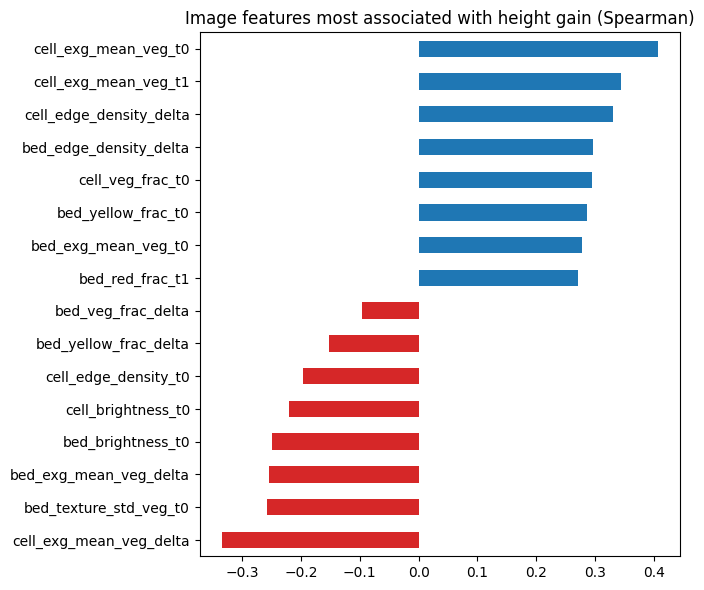

In [10]:
# What do the hand-crafted features say? (Spearman with the target; descriptive only)
corr = data_img[HC_FEATS + ['y']].corr(method='spearman')['y'].drop('y').sort_values()
top = pd.concat([corr.head(8), corr.tail(8)])
fig, ax = plt.subplots(figsize=(7, 6))
top.plot.barh(ax=ax, color=['C3' if v < 0 else 'C0' for v in top])
ax.set_title('Image features most associated with height gain (Spearman)')
plt.tight_layout(); plt.show()

## 6b. Does a cell really describe its own plant?

If the 2 × 3 grid places each plant correctly, a cell's features on t0 should agree with **that plant's** manual
measurements on t0 (leaf size, LAI, NDVI…) better than with a random neighbour's. Test: Spearman correlation between
cell feature and manual measurement across the 60 plants, compared with 2000 permutations where plant labels are
shuffled **within each bed** (so only the position inside the bed is broken, not differences between beds).

In [11]:
rng = np.random.default_rng(SEED)
CELL_F = ['cell_veg_frac_t0', 'cell_exg_mean_veg_t0', 'cell_texture_std_veg_t0', 'cell_edge_density_t0']
MANUAL = [c for c in ['LAI_t0', 'Leaf Length_t0', 'Leaf Width_t0', 'NDVI_t0', 'Stem Diameter_t0', 'Plant Height_t0'] if c in data_img]
bed_key = data_img['folder'].astype(str) + data_img['bed'].astype(str)
idx_by_bed = [np.where(bed_key.values == b)[0] for b in bed_key.unique()]

from scipy.stats import rankdata

rows = []
for cf in CELL_F:
    for mf in MANUAL:
        ok = data_img[cf].notna() & data_img[mf].notna()
        rx = rankdata(data_img[cf].where(ok)).astype(float)       # ranks once; permuting keeps them valid
        ry = rankdata(data_img[mf].where(ok)).astype(float)
        obs = np.corrcoef(rx, ry)[0, 1]
        null = np.empty(2000)
        for k in range(2000):
            perm = np.arange(len(rx))
            for idx in idx_by_bed:
                perm[idx] = rng.permutation(idx)
            null[k] = np.corrcoef(rx[perm], ry)[0, 1]
        rows.append({'cell feature': cf, 'manual measurement': mf, 'rho (true position)': obs,
                     'rho shuffled within bed (mean)': null.mean(),
                     'p (|null| >= |obs|)': (np.abs(null) >= abs(obs)).mean()})
validation = pd.DataFrame(rows).sort_values('p (|null| >= |obs|)')
display(validation.round(3))
print('pairs with p < 0.05:', (validation['p (|null| >= |obs|)'] < 0.05).sum(), 'of', len(validation),
      '(about', round(0.05 * len(validation), 1), 'expected by chance)')
validation.to_csv(OUT_DIR / 'cell_mapping_validation.csv', index=False)

,cell feature,manual measurement,rho (true position),rho shuffled within bed (mean),p (|null| >= |obs|)
0,cell_veg_frac_t0,LAI_t0,0.365,0.175,0.012
22,cell_edge_density_t0,Stem Diameter_t0,-0.235,-0.024,0.054
5,cell_veg_frac_t0,Plant Height_t0,0.201,0.058,0.063
4,cell_veg_frac_t0,Stem Diameter_t0,0.215,0.106,0.138
17,cell_texture_std_veg_t0,Plant Height_t0,0.246,0.161,0.171
9,cell_exg_mean_veg_t0,NDVI_t0,0.161,0.072,0.180
23,cell_edge_density_t0,Plant Height_t0,-0.174,-0.080,0.191
3,cell_veg_frac_t0,NDVI_t0,0.218,0.138,0.192
19,cell_edge_density_t0,Leaf Length_t0,-0.169,-0.069,0.202
6,cell_exg_mean_veg_t0,LAI_t0,0.140,0.066,0.227


pairs with p < 0.05: 1 of 24 (about 1.2 expected by chance)


How to read it: if only about as many pairs pass p < 0.05 as expected by chance, the cell grid does **not** isolate
individual plants (overlapping canopy) and cell-level image features should be treated as bed-level information.
That would be an honest limitation to report — and part of the reason the image model cannot predict individual plants.

## 7. Image-only models

Same target `y` (height gain 7→13 June) and the **same CV schemes** as notebook 02, so the numbers are directly comparable.
The 2048-dim embeddings go through StandardScaler → PCA(10 components) **inside** each training fold.

In [12]:
from sklearn.pipeline import make_pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.impute import SimpleImputer
from sklearn.linear_model import RidgeCV
from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import RepeatedKFold, LeaveOneGroupOut
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

N_PCA = 10

def preprocessor(hc_cols, emb_cols):
    parts = []
    if hc_cols:
        parts.append(('hc', make_pipeline(SimpleImputer(strategy='median'), StandardScaler()), hc_cols))
    if emb_cols:
        parts.append(('emb', make_pipeline(StandardScaler(), PCA(n_components=N_PCA, random_state=SEED)), emb_cols))
    return ColumnTransformer(parts)

def ridge(hc, em):
    return make_pipeline(preprocessor(hc, em), RidgeCV(alphas=np.logspace(-2, 3, 30)))
def forest(hc, em):
    return make_pipeline(preprocessor(hc, em),
                         RandomForestRegressor(n_estimators=500, min_samples_leaf=3, random_state=SEED))

y = data_img['y'].values
groups = data_img['camera'].astype(str).values

def oof_predict(make_model, X, scheme):
    pred_sum, pred_n = np.zeros(len(y)), np.zeros(len(y))
    splits = (RepeatedKFold(n_splits=5, n_repeats=10, random_state=SEED).split(X) if scheme == 'kfold'
              else LeaveOneGroupOut().split(X, y, groups))
    for tr, te in splits:
        m = make_model().fit(X.iloc[tr], y[tr])
        pred_sum[te] += m.predict(X.iloc[te]); pred_n[te] += 1
    return pred_sum / pred_n

def scores(pred):
    return {'MAE': mean_absolute_error(y, pred), 'RMSE': mean_squared_error(y, pred) ** 0.5, 'R2': r2_score(y, pred)}

IMAGE_SETS = {
    'image_handcrafted': (HC_FEATS, []),
    'image_cnn': ([], EMB_FEATS),
    'image_all': (HC_FEATS, EMB_FEATS),
    'image_t0_only_handcrafted': (HC_T0, []),        # forecast: only what is visible on 7 June
    'image_t0_only_all': (HC_T0, EMB_T0),
}
results, oof = [], {}
for scheme in ['kfold', 'leave_camera_out']:
    for name, (hc, em) in IMAGE_SETS.items():
        X = data_img[hc + em]
        for model_name, mk in [('ridge', ridge), ('random_forest', forest)]:
            p = oof_predict(lambda: mk(hc, em), X, scheme)
            results.append({'scheme': scheme, 'features': name, 'model': model_name, **scores(p)})
            oof[(scheme, f'{name}|{model_name}')] = p

res_img = pd.DataFrame(results)
res_num = pd.read_csv(OUT_DIR / 'results_numerical.csv')
comparison = pd.concat([res_num, res_img], ignore_index=True).sort_values(['scheme', 'R2'], ascending=[True, False])
display(comparison.round(3))

,scheme,features,model,MAE,RMSE,R2
6,kfold,numerical (phenotype + sensor),random_forest,6.643,9.279,0.246
5,kfold,numerical (phenotype + sensor),ridge,6.950,9.513,0.208
19,kfold,image_all,random_forest,7.196,9.567,0.199
23,kfold,image_t0_only_all,random_forest,7.171,9.732,0.171
15,kfold,image_handcrafted,random_forest,7.188,9.780,0.163
17,kfold,image_cnn,random_forest,7.511,9.862,0.149
21,kfold,image_t0_only_handcrafted,random_forest,7.257,9.922,0.138
2,kfold,phenotype_only,random_forest,7.419,10.057,0.115
1,kfold,phenotype_only,ridge,7.499,10.130,0.102
14,kfold,image_handcrafted,ridge,7.799,10.399,0.053


How to read it:
- Compare `image_*` rows with `baseline` and with the numerical rows **within the same CV scheme**.
- `image_t0_only_*` uses only the 7 June images: a real forecast. `image_handcrafted/cnn/all` also use 13 June images,
  i.e. they *estimate* the growth that already happened from the camera (useful for monitoring, but not a forecast).
- The image only sees the canopy from above: it can see leaf area, flowers, fruits, pruning, damage —
  but **not plant height directly** (top-down camera). So a weak image-only score for *height* gain is expected and is itself a finding.

## 8. Look at two interesting plants

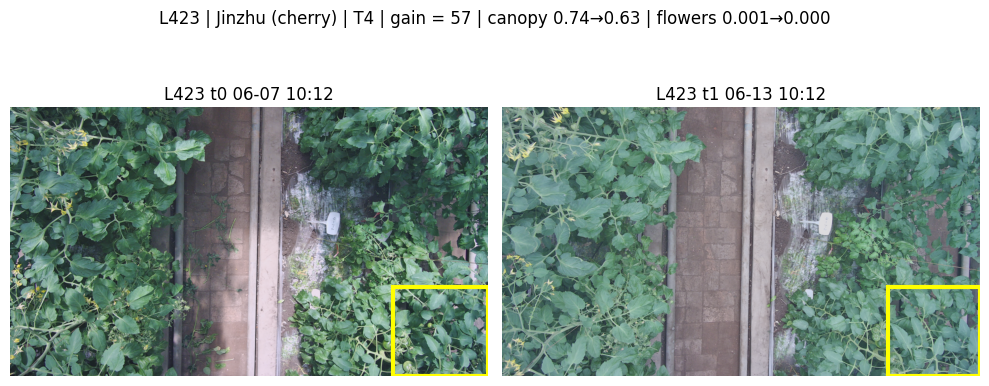

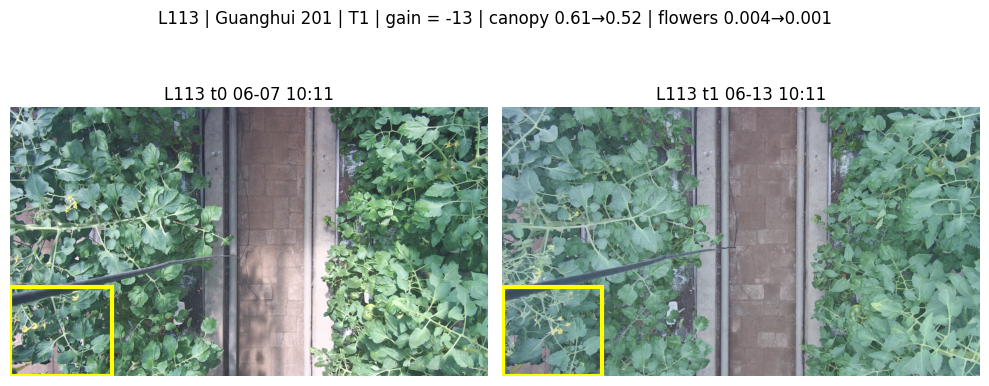

In [13]:
def show_plant(plant):
    pos = layout[layout.plant == plant].iloc[0]
    fig, axes = plt.subplots(1, 2, figsize=(10, 4.5))
    for ax, day in zip(axes, ['t0', 't1']):
        r = sel[(sel.folder == pos.folder) & (sel.day == day)].iloc[0]
        raw = load(r.path); veg, *_ = colour_masks(raw); x0, x1 = find_walkway(veg); a = normalise(raw, r.path)
        y0, y1, xa, xb = regions(a, x0, x1)[(pos.bed, pos.col, pos.row)]
        ax.imshow(a); ax.add_patch(plt.Rectangle((xa, y0), xb - xa, y1 - y0, fill=False, ec='yellow', lw=3))
        ax.set_title(f'{plant} {day} {r.capture_local:%m-%d %H:%M}'); ax.axis('off')
    row = data_img[data_img.plant == plant].iloc[0]
    fig.suptitle(f"{plant} | {row.variety_name} | {row.treatment} | gain = {row.y:.0f} | "
                 f"canopy {row.cell_veg_frac_t0:.2f}→{row.cell_veg_frac_t1:.2f} | flowers {row.cell_yellow_frac_t0:.3f}→{row.cell_yellow_frac_t1:.3f}")
    plt.tight_layout(); plt.show()

for p in ['L423', 'L113']:      # biggest under- and over-estimation of the numerical model
    if p in set(layout.plant):
        show_plant(p)

In [14]:
# Save for notebook 04 (fusion + error analysis)
keep = ['plant'] + HC_FEATS + list(emb_df.columns)
data_img[keep].to_parquet(OUT_DIR / 'image_features_plant.parquet', index=False)
res_img.to_csv(OUT_DIR / 'results_image.csv', index=False)
pd.DataFrame({'plant': data_img.plant, **{k[1]: v for k, v in oof.items() if k[0] == 'leave_camera_out'}}) \
  .to_parquet(OUT_DIR / 'oof_image_leave_camera_out.parquet', index=False)
print('Saved:', sorted(p.name for p in OUT_DIR.iterdir()))

Saved: ['bootstrap_comparison.csv', 'cell_mapping_validation.csv', 'figures', 'growth_daily.parquet', 'growth_measured_all.parquet', 'image_features_plant.parquet', 'image_index.parquet', 'image_region_embeddings.npy', 'image_region_embeddings_v2.npy', 'image_region_features.parquet', 'image_region_features_v2.parquet', 'image_regions.parquet', 'model_table_numerical.parquet', 'oof_image_leave_camera_out.parquet', 'plant_map.csv', 'predictions_per_plant.csv', 'results_final.csv', 'results_image.csv', 'results_numerical.csv', 'results_numerical_108.csv', 'sensors_long.parquet', 'sensors_zone_30min.parquet', 'target_window.json']
